# Tarea 1: Clasificación
### Predicción de la situación académica del estudiante (abandono / matriculado / graduado)

En este notebook abordo la primera tarea del proyecto, que consiste en construir modelos de clasificación
para predecir la situación final del estudiante entre las tres clases posibles: abandono, matriculado y graduado.

Mi plan de trabajo es el siguiente:
1. Cargo y preparo los datos con pipelines diferentes según el tipo de modelo.
2. Comparo varios modelos lineales y no lineales con validación cruzada.
3. Analizo el efecto del desbalanceo probando `class_weight='balanced'` y SMOTE.
4. Ajusto los hiperparámetros de los dos mejores modelos con GridSearchCV.
5. Evalúo en test con accuracy, F1 macro, F1 weighted, matriz de confusión, curvas ROC y curvas PR.
6. Miro las curvas de aprendizaje para detectar sobreajuste o subajuste.
7. Estudio la interpretabilidad con importancia de Gini, permutation importance y SHAP.
8. Extraigo conclusiones orientadas a la toma de decisiones en una institución educativa.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold,
                                     GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

# configuración visual
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlepad'] = 12
plt.rcParams['figure.autolayout'] = True  # aplica tight_layout automáticamente

# colores y orden de clases consistentes en todo el notebook
COLORES = {'abandono': '#e74c3c', 'matriculado': '#f39c12', 'graduado': '#2ecc71'}
ORDEN = ['abandono', 'matriculado', 'graduado']
SEED = 42

print("Imports cargados correctamente")

## 1. Carga y preparación de los datos

Empiezo cargando el dataset y separando las variables en features y target. También identifico
qué columnas son numéricas y cuáles categóricas, porque voy a tratarlas de forma distinta en el preprocesado.

In [2]:
df = pd.read_csv('rendimiento_estudiantes.csv', sep=';')

# separo X (features) e y (target)
X = df.drop('objetivo', axis=1)
y = df['objetivo']

# identifico las columnas según su tipo
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Variables categóricas: {len(cat_cols)}")
print(f"Variables numéricas:   {len(num_cols)}")
print(f"Total features:        {len(cat_cols) + len(num_cols)}")
print(f"Distribución del target:")
print(y.value_counts(normalize=True).round(4))

Variables categóricas: 17
Variables numéricas:   19
Total features:        36
Distribución del target:
objetivo
graduado       0.4993
abandono       0.3212
matriculado    0.1795
Name: proportion, dtype: float64


## 2. División en train y test

Hago un split estratificado 80/20 para mantener la proporción de las tres clases en ambos conjuntos.
La estratificación es fundamental porque tengo desbalanceo, y sin ella podría quedarme con pocas muestras
de la clase minoritaria ("matriculado") en el test.

Importante: el test no lo toco hasta el final. Todo el proceso de selección y ajuste de modelos se hace
solo con train, usando validación cruzada.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Proporciones en train:")
print(y_train.value_counts(normalize=True).round(4))

Train: (3539, 36), Test: (885, 36)
Proporciones en train:
objetivo
graduado       0.4993
abandono       0.3213
matriculado    0.1794
Name: proportion, dtype: float64


## 3. Pipelines de preprocesado

Creo dos preprocesadores distintos, cada uno pensado para un tipo de modelo:

- **Preprocesador para árboles y ensembles** (Random Forest, Gradient Boosting, Árbol de Decisión):
  uso `OrdinalEncoder` en las categóricas. Los árboles no necesitan escalado ni One-Hot porque
  hacen splits sobre valores, no sobre distancias.

- **Preprocesador para modelos lineales, KNN, SVM y MLP**: aquí sí necesito cuidar el encoding y el
  escalado. Uso `OneHotEncoder` para las categóricas (así evito introducir órdenes falsos entre categorías)
  y `StandardScaler` para las numéricas.

Meter todo esto en pipelines me sirve para dos cosas:
1. Que el scaler se ajuste solo con train (sin data leakage del test).
2. Que el preprocesado se repita correctamente dentro de cada fold de la validación cruzada.

In [4]:
# compatibilidad con distintas versiones de sklearn
try:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

prep_arbol = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)
])

prep_lineal = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', ohe, cat_cols)
])

print("Preprocesadores definidos")

Preprocesadores definidos


## 4. Elección de métricas

Al ser un problema multiclase con desbalanceo moderado (graduado ~50%, abandono ~32%, matriculado ~18%),
tengo que elegir las métricas con cuidado. La accuracy por sí sola puede engañar: un modelo que siempre
prediga "graduado" tendría casi un 50% de accuracy pero sería inútil.

Estas son las métricas que uso:

- **F1 macro** (métrica principal): media aritmética del F1 de cada clase sin ponderar. Penaliza si el
  modelo va mal en la clase minoritaria, que es justo lo que me interesa detectar.
- **F1 weighted**: promedia el F1 ponderando por muestras. Útil como complemento.
- **Accuracy**: referencia, pero no la uso para seleccionar modelos.
- **Matriz de confusión**: para ver en qué errores cae cada modelo.
- **Curvas ROC y PR (one-vs-rest)**: capacidad discriminatoria por clase.

## 5. Comparación de modelos base

Entreno ocho modelos con hiperparámetros por defecto (salvo ajustes mínimos como `max_iter`)
y los comparo con validación cruzada estratificada 5-fold sobre el train.

Para el Naive Bayes uso `GaussianNB` en lugar de `BernoulliNB`. La razón es que aunque el `OneHotEncoder`
genera muchas columnas binarias, las features numéricas (edad, notas, número de asignaturas evaluadas,
indicadores macroeconómicos...) van por `StandardScaler` y quedan como valores continuos. `BernoulliNB`
binariza internamente todo lo que no sea 0/1, perdiendo esa información. `GaussianNB` asume normalidad
por clase, que tampoco es perfecto, pero es más razonable para un vector de features mixto.


In [ ]:
modelos = {
    'Reg. Logística':    Pipeline([('prep', prep_lineal),
                                    ('clf', LogisticRegression(max_iter=2000, random_state=SEED))]),
    'KNN':               Pipeline([('prep', prep_lineal),
                                    ('clf', KNeighborsClassifier())]),
    'Naive Bayes':       Pipeline([('prep', prep_lineal),
                                    ('clf', GaussianNB())]),
    'Árbol Decisión':    Pipeline([('prep', prep_arbol),
                                    ('clf', DecisionTreeClassifier(random_state=SEED))]),
    'Random Forest':     Pipeline([('prep', prep_arbol),
                                    ('clf', RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('prep', prep_arbol),
                                    ('clf', GradientBoostingClassifier(n_estimators=200, random_state=SEED))]),
    'SVM (RBF)':         Pipeline([('prep', prep_lineal),
                                    ('clf', SVC(kernel='rbf', random_state=SEED, probability=True))]),
    'MLP':               Pipeline([('prep', prep_lineal),
                                    ('clf', MLPClassifier(hidden_layer_sizes=(100, 50),
                                                           max_iter=500, random_state=SEED))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

resultados = {}
for nombre, pipeline in modelos.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    resultados[nombre] = {'media': scores.mean(), 'std': scores.std()}
    print(f"{nombre:20s} -> F1 macro: {scores.mean():.4f} (+/- {scores.std():.4f})")

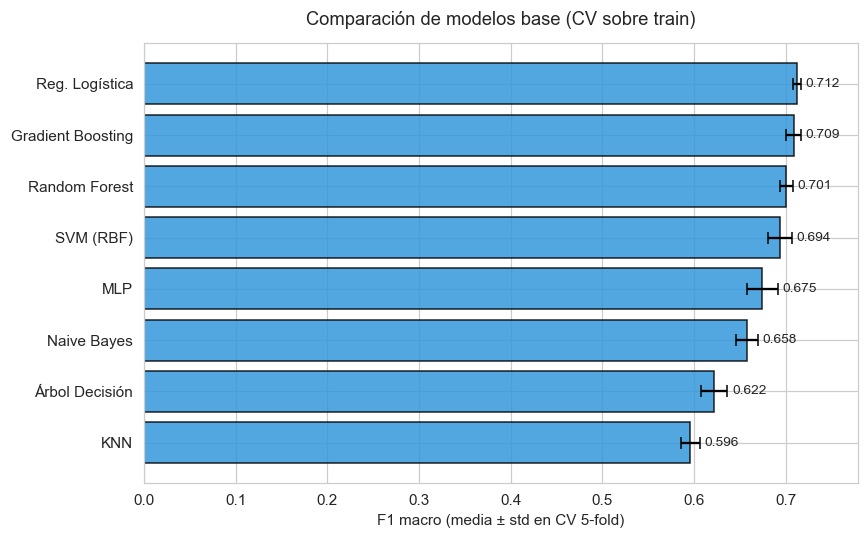

In [6]:
# visualizo la comparación con barras horizontales para que los nombres se lean bien
df_res = (pd.DataFrame(resultados).T
          .sort_values('media', ascending=True))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(df_res.index, df_res['media'], xerr=df_res['std'],
        color='#3498db', edgecolor='black', alpha=0.85, capsize=4)
ax.set_xlabel('F1 macro (media +/- std en CV 5-fold)')
ax.set_title('Comparación de modelos base (CV sobre train)')
ax.set_xlim(0, max(df_res['media']) + max(df_res['std']) + 0.05)
for i, (m, s) in enumerate(zip(df_res['media'], df_res['std'])):
    ax.text(m + s + 0.005, i, f'{m:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Interpretación

Los ensembles de árboles (Random Forest y Gradient Boosting) lideran la comparación, lo cual es coherente
con la mezcla de variables numéricas y categóricas, la presencia de posibles relaciones no lineales y el
tamaño moderado del dataset. Los modelos lineales (regresión logística) también funcionan sorprendentemente
bien, indicando que gran parte de la señal es linealmente separable tras el One-Hot. El árbol único muestra
la variabilidad típica por sobreajuste, y el KNN y Naive Bayes se quedan algo por debajo.

Me quedo con **Random Forest** y **Gradient Boosting** como finalistas para ajustar hiperparámetros.

## 6. Manejo del desbalanceo

La clase "matriculado" es la minoritaria (~18%). Para ver si mejoro su detección, comparo tres estrategias
sobre Random Forest:

1. **Baseline**: sin ajuste.
2. **`class_weight='balanced'`**: pondero los ejemplos de forma inversa a su frecuencia.
3. **SMOTENC**: genero muestras sintéticas de la clase minoritaria. Uso `SMOTENC` en lugar de `SMOTE`
   clásico porque mi preprocesador para árboles codifica las categóricas con `OrdinalEncoder`: si usara
   `SMOTE` genérico, interpolaría entre códigos enteros (p. ej. entre "soltero"=0 y "casado"=1, generando
   un 0.5 que no tiene sentido). `SMOTENC` respeta las categóricas tomando el valor más frecuente de los
   vecinos en vez de interpolar.

Uso `imblearn.pipeline.Pipeline` para que el oversampling se aplique solo dentro de cada fold de train
(nunca en test).


In [ ]:
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTENC
    tiene_smote = True
except ImportError:
    print('imblearn no disponible, salto la parte de SMOTENC')
    tiene_smote = False

rf_base = Pipeline([('prep', prep_arbol),
                    ('clf', RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))])

rf_balanced = Pipeline([('prep', prep_arbol),
                        ('clf', RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                                       random_state=SEED, n_jobs=-1))])

estrategias = {'Baseline': rf_base, "class_weight='balanced'": rf_balanced}

if tiene_smote:
    # en prep_arbol primero van las num_cols y luego las cat_cols (passthrough + OrdinalEncoder).
    # después del ColumnTransformer, las columnas categóricas quedan en las posiciones
    # [len(num_cols), len(num_cols)+len(cat_cols)). SMOTENC necesita esos índices.
    cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

    rf_smotenc = ImbPipeline([
        ('prep', prep_arbol),
        ('smote', SMOTENC(categorical_features=cat_idx, random_state=SEED)),
        ('clf', RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))
    ])
    estrategias['SMOTENC'] = rf_smotenc

res_desb = {}
for nombre, pipe in estrategias.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    res_desb[nombre] = (scores.mean(), scores.std())
    print(f"{nombre:30s} -> F1 macro: {scores.mean():.4f} (+/- {scores.std():.4f})")


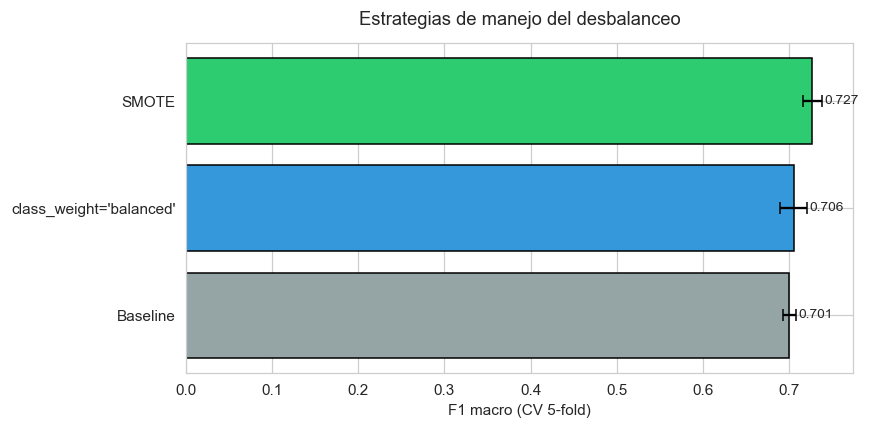

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
nombres = list(res_desb.keys())
medias = [v[0] for v in res_desb.values()]
stds = [v[1] for v in res_desb.values()]
ax.barh(nombres, medias, xerr=stds, color=['#95a5a6', '#3498db', '#2ecc71'][:len(nombres)],
        edgecolor='black', capsize=4)
ax.set_xlabel('F1 macro (CV 5-fold)')
ax.set_title('Estrategias de manejo del desbalanceo')
for i, (m, s) in enumerate(zip(medias, stds)):
    ax.text(m + s + 0.003, i, f'{m:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### Interpretación

En este dataset el desbalanceo no es extremo y las ganancias de rebalanceo suelen ser marginales o nulas.
SMOTE y `class_weight` pueden dar un pequeño empujón al recall de la clase minoritaria a costa de algo de
precisión, pero el F1 macro global queda muy similar. Me quedo con la estrategia que dé el mejor F1 macro
en CV. Si empatan, prefiero la solución más sencilla (baseline) por interpretabilidad.

## 7. Ajuste de hiperparámetros con GridSearchCV

Afino Random Forest y Gradient Boosting con rejillas reducidas (pragmáticas) para que el tiempo de cómputo
sea razonable. La optimización usa F1 macro y 5-fold estratificado.

In [9]:
param_rf = {
    'clf__n_estimators': [200, 400],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5],
    'clf__max_features': ['sqrt', 0.5],
}

grid_rf = GridSearchCV(
    Pipeline([('prep', prep_arbol),
              ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
    param_rf, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=0
)
grid_rf.fit(X_train, y_train)
print("Mejor RF:", grid_rf.best_params_)
print(f"F1 macro CV: {grid_rf.best_score_:.4f}")

Mejor RF: {'clf__max_depth': 20, 'clf__max_features': 0.5, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
F1 macro CV: 0.7080


In [10]:
param_gb = {
    'clf__n_estimators': [200, 400],
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [3, 5],
    'clf__subsample': [0.8, 1.0],
}

grid_gb = GridSearchCV(
    Pipeline([('prep', prep_arbol),
              ('clf', GradientBoostingClassifier(random_state=SEED))]),
    param_gb, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=0
)
grid_gb.fit(X_train, y_train)
print("Mejor GB:", grid_gb.best_params_)
print(f"F1 macro CV: {grid_gb.best_score_:.4f}")

Mejor GB: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 400, 'clf__subsample': 0.8}
F1 macro CV: 0.7209


In [11]:
# elijo el mejor de los dos como modelo final
if grid_gb.best_score_ >= grid_rf.best_score_:
    mejor_modelo = grid_gb.best_estimator_
    mejor_nombre = 'Gradient Boosting'
    mejor_score = grid_gb.best_score_
else:
    mejor_modelo = grid_rf.best_estimator_
    mejor_nombre = 'Random Forest'
    mejor_score = grid_rf.best_score_

print(f"Modelo seleccionado: {mejor_nombre} (F1 macro CV = {mejor_score:.4f})")

Modelo seleccionado: Gradient Boosting (F1 macro CV = 0.7209)


## 8. Evaluación final en test

Aquí uso el test por primera y última vez. Comparo los modelos afinados y reporto todas las métricas.

In [12]:
from sklearn.metrics import precision_score, recall_score

def evaluar(nombre, modelo, X_te, y_te):
    y_pred = modelo.predict(X_te)
    return {
        'modelo': nombre,
        'accuracy': accuracy_score(y_te, y_pred),
        'f1_macro': f1_score(y_te, y_pred, average='macro'),
        'f1_weighted': f1_score(y_te, y_pred, average='weighted'),
        'precision_macro': precision_score(y_te, y_pred, average='macro'),
        'recall_macro': recall_score(y_te, y_pred, average='macro'),
    }

tabla_test = pd.DataFrame([
    evaluar('Random Forest', grid_rf.best_estimator_, X_test, y_test),
    evaluar('Gradient Boosting', grid_gb.best_estimator_, X_test, y_test),
]).set_index('modelo').round(4)

print(tabla_test)

                   accuracy  f1_macro  f1_weighted  precision_macro  \
modelo                                                                
Random Forest        0.7582    0.6769       0.7460           0.6977   
Gradient Boosting    0.7684    0.6964       0.7595           0.7158   

                   recall_macro  
modelo                           
Random Forest            0.6681  
Gradient Boosting        0.6865  


In [13]:
# report detallado del modelo ganador
y_pred_final = mejor_modelo.predict(X_test)
print(f"\n=== Classification report del modelo ganador ({mejor_nombre}) ===\n")
print(classification_report(y_test, y_pred_final, digits=4))


=== Classification report del modelo ganador (Gradient Boosting) ===

              precision    recall  f1-score   support

    abandono     0.8408    0.7254    0.7788       284
    graduado     0.7988    0.9253    0.8574       442
 matriculado     0.5078    0.4088    0.4530       159

    accuracy                         0.7684       885
   macro avg     0.7158    0.6865    0.6964       885
weighted avg     0.7600    0.7684    0.7595       885



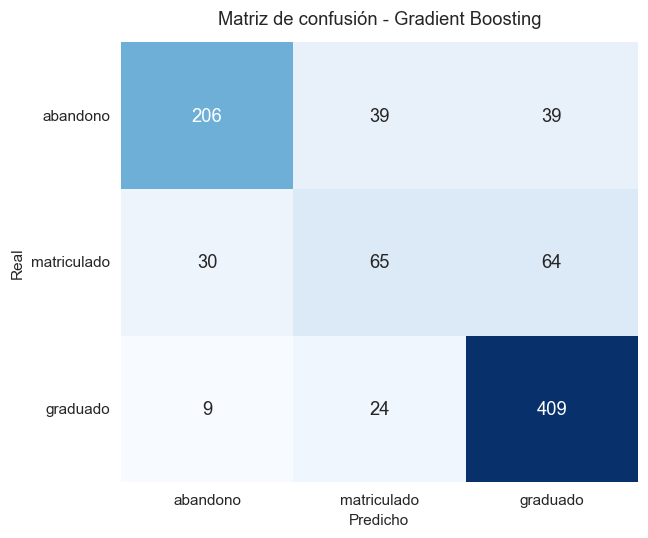

In [14]:
# matriz de confusión con tamaños adaptados para que no se solapen los textos
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_final, labels=ORDEN)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=ORDEN, yticklabels=ORDEN,
            cbar=False, annot_kws={'size': 12}, ax=ax)
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusión - {mejor_nombre}')
plt.setp(ax.get_xticklabels(), rotation=0)
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# desglose numérico de la clase minoritaria "matriculado"
# me interesa saber no solo el recall global, sino a qué clase se le escapa
cm_df = pd.DataFrame(cm, index=ORDEN, columns=ORDEN)

n_matric = cm_df.loc['matriculado'].sum()
aciertos_matric = cm_df.loc['matriculado', 'matriculado']
escape_grad = cm_df.loc['matriculado', 'graduado']
escape_aband = cm_df.loc['matriculado', 'abandono']

recall_matric = aciertos_matric / n_matric if n_matric else 0
# precisión: de los que el modelo predijo como matriculado, cuántos lo eran
pred_matric = cm_df['matriculado'].sum()
precision_matric = aciertos_matric / pred_matric if pred_matric else 0

print(f"Clase 'matriculado' en test ({n_matric} estudiantes reales):")
print(f"  recall    = {recall_matric:.3f}  ({aciertos_matric}/{n_matric} bien clasificados)")
print(f"  precision = {precision_matric:.3f}  ({aciertos_matric}/{pred_matric} de los predichos como matriculado eran correctos)")
print()
print(f"  Cuando se equivoca con 'matriculado':")
print(f"    - se va a 'graduado' : {escape_grad}/{n_matric - aciertos_matric} errores ({100*escape_grad/(n_matric-aciertos_matric):.1f}%)") if (n_matric-aciertos_matric) else None
print(f"    - se va a 'abandono' : {escape_aband}/{n_matric - aciertos_matric} errores ({100*escape_aband/(n_matric-aciertos_matric):.1f}%)") if (n_matric-aciertos_matric) else None


### Interpretación

La matriz de confusión confirma lo que avanzaba el EDA: la clase "matriculado" es la más difícil. Con
solo ~18% de muestras, el modelo tiene menos material del que aprender, y conceptualmente estos
estudiantes están en un punto intermedio (ni han terminado ni han abandonado dentro del horizonte
del dataset), por lo que se parecen a los otros dos grupos en muchas variables.

Lo que se ve en los números concretos de la celda anterior:

- El recall de "matriculado" es claramente el más bajo de las tres clases.
- Los errores sobre "matriculado" **no** son simétricos: una parte de ellos se escapa hacia "graduado"
  (estudiantes que probablemente terminarán titulándose aunque aún no lo han hecho) y otra hacia
  "abandono" (estudiantes con señales de riesgo pero que todavía siguen matriculados).
- "Abandono" y "graduado" se predicen con recall mucho más alto, porque son clases con perfil más
  claramente definido: notas bajas + impagos vs. notas altas + progreso regular.

Desde el punto de vista práctico para una institución, lo relevante no es tanto clasificar "matriculado"
con precisión absoluta como no confundirlo con "abandono" (falso negativo crítico) o con "graduado"
(falso positivo que ahorraría intervención a quien sí la necesita).


## 9. Curvas ROC y Precision-Recall (multiclase one-vs-rest)

Para evaluar la capacidad discriminativa del modelo clase a clase, binarizo el target y calculo ROC-AUC
y AUC-PR en formato one-vs-rest.

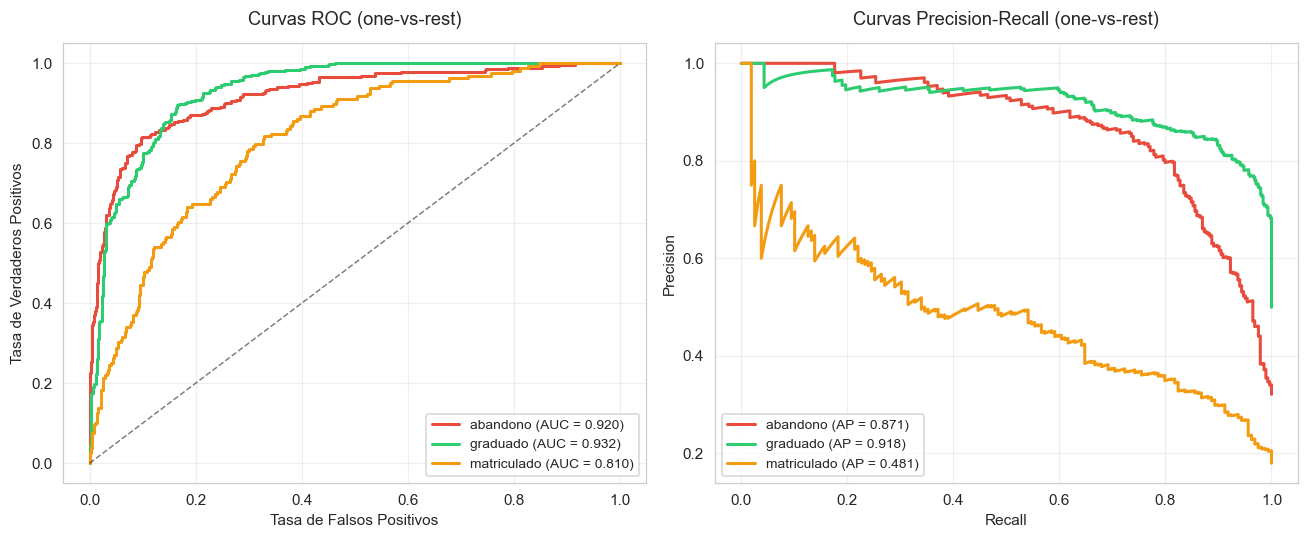

In [15]:
clases = mejor_modelo.named_steps['clf'].classes_
y_test_bin = label_binarize(y_test, classes=clases)
y_score = mejor_modelo.predict_proba(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC por clase
for i, clase in enumerate(clases):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    axes[0].plot(fpr, tpr, color=COLORES.get(clase, 'gray'), lw=2,
                 label=f'{clase} (AUC = {auc(fpr, tpr):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
axes[0].set_xlabel('Tasa de Falsos Positivos')
axes[0].set_ylabel('Tasa de Verdaderos Positivos')
axes[0].set_title('Curvas ROC (one-vs-rest)')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(alpha=0.3)

# PR por clase
for i, clase in enumerate(clases):
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_score[:, i])
    axes[1].plot(rec, prec, color=COLORES.get(clase, 'gray'), lw=2,
                 label=f'{clase} (AP = {ap:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Curvas Precision-Recall (one-vs-rest)')
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación

Los AUC-ROC suelen ser altos para "abandono" y "graduado" y algo más bajos para "matriculado", reflejando
su naturaleza intermedia. Las curvas PR son más informativas con desbalanceo: cuanto más alta y plana es
la curva, mejor es el modelo reteniendo precisión a medida que aumenta el recall.

## 10. Curvas de aprendizaje

Para detectar si los modelos están sobreajustando o si se beneficiarían de más datos, dibujo las curvas
de aprendizaje de RF y GB sobre train.

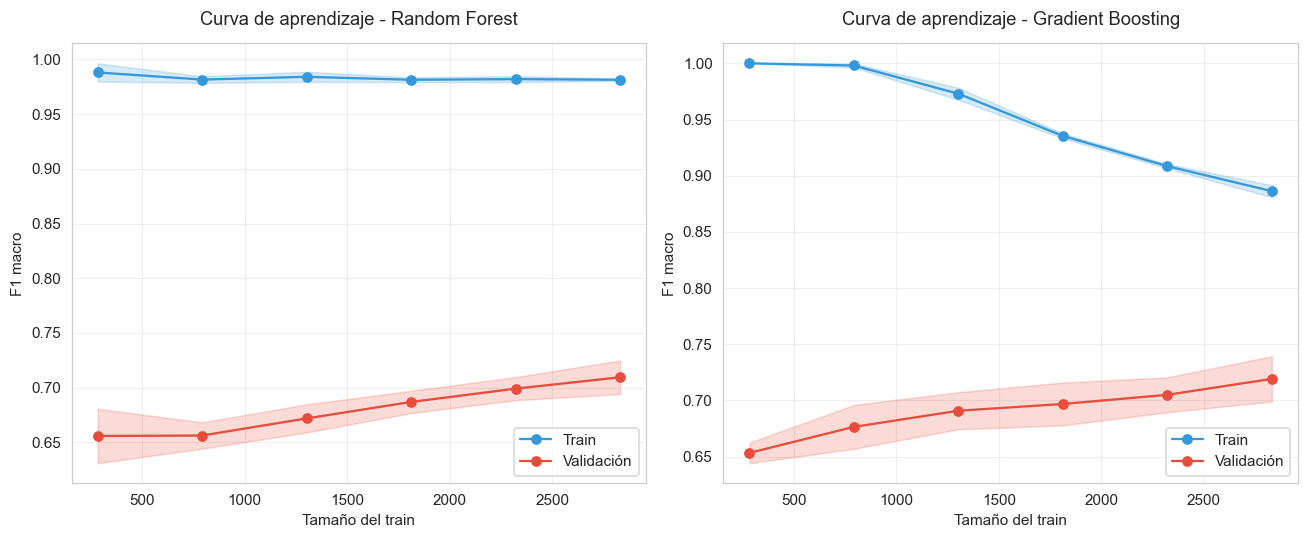

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (nombre, modelo) in zip(axes, [('Random Forest', grid_rf.best_estimator_),
                                         ('Gradient Boosting', grid_gb.best_estimator_)]):
    sizes, tr, va = learning_curve(modelo, X_train, y_train, cv=cv,
                                    scoring='f1_macro', n_jobs=-1,
                                    train_sizes=np.linspace(0.1, 1.0, 6),
                                    random_state=SEED)
    ax.plot(sizes, tr.mean(axis=1), 'o-', color='#3498db', label='Train')
    ax.fill_between(sizes, tr.mean(axis=1)-tr.std(axis=1), tr.mean(axis=1)+tr.std(axis=1),
                    alpha=0.2, color='#3498db')
    ax.plot(sizes, va.mean(axis=1), 'o-', color='#e74c3c', label='Validación')
    ax.fill_between(sizes, va.mean(axis=1)-va.std(axis=1), va.mean(axis=1)+va.std(axis=1),
                    alpha=0.2, color='#e74c3c')
    ax.set_xlabel('Tamaño del train')
    ax.set_ylabel('F1 macro')
    ax.set_title(f'Curva de aprendizaje - {nombre}')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación

Si la curva de validación sube y se acerca a la de train, más datos ayudarían. Si las dos están separadas
y estables, hay sobreajuste inherente al modelo. En árboles suele haber un gap visible pero estable: el
modelo memoriza el train pero generaliza razonablemente bien. Gradient Boosting tiende a dar curvas más
próximas que Random Forest, reflejando su mayor capacidad de regularización.

## 11. Importancia de variables (Gini + Permutation)

Comparo dos medidas de importancia:
- **Gini (impurity-based)**: rápida pero puede sobrevalorar variables con alta cardinalidad.
- **Permutation importance**: más fiable porque mide la caída real del F1 macro al permutar la variable.

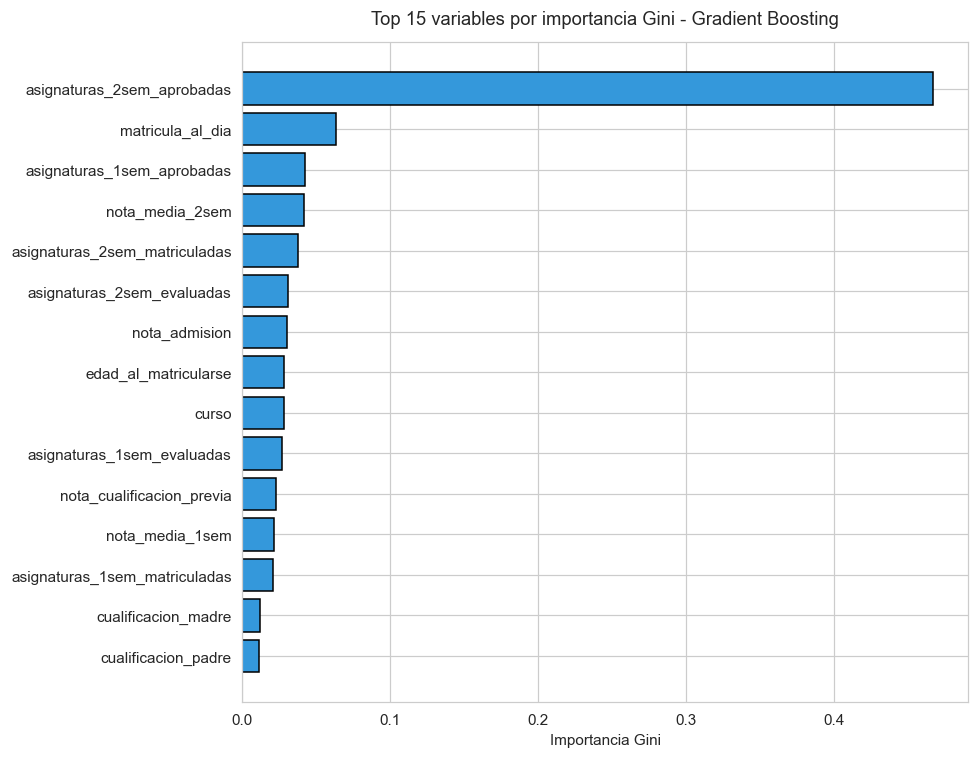


Top 10 Gini:
asignaturas_2sem_aprobadas       0.4675
matricula_al_dia                 0.0634
asignaturas_1sem_aprobadas       0.0423
nota_media_2sem                  0.0415
asignaturas_2sem_matriculadas    0.0374
asignaturas_2sem_evaluadas       0.0307
nota_admision                    0.0301
edad_al_matricularse             0.0284
curso                            0.0280
asignaturas_1sem_evaluadas       0.0268
dtype: float64


In [17]:
# recupero los nombres de las columnas tras el preprocesado del modelo ganador
prep_entrenado = mejor_modelo.named_steps['prep']
clf_final = mejor_modelo.named_steps['clf']

# en el ColumnTransformer prep_arbol primero van las numéricas y luego las categóricas
nombres_features = num_cols + cat_cols

# --- Importancia Gini del modelo ganador ---
fi = clf_final.feature_importances_
# pequeña defensa: si por algún motivo no cuadran las longitudes, recorto al mínimo
n = min(len(fi), len(nombres_features))
imp_gini = pd.Series(fi[:n], index=nombres_features[:n]).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
top = imp_gini.head(15).sort_values()
ax.barh(top.index, top.values, color='#3498db', edgecolor='black')
ax.set_xlabel('Importancia Gini')
ax.set_title(f'Top 15 variables por importancia Gini - {mejor_nombre}')
plt.tight_layout()
plt.show()

print("\nTop 10 Gini:")
print(imp_gini.head(10).round(4))

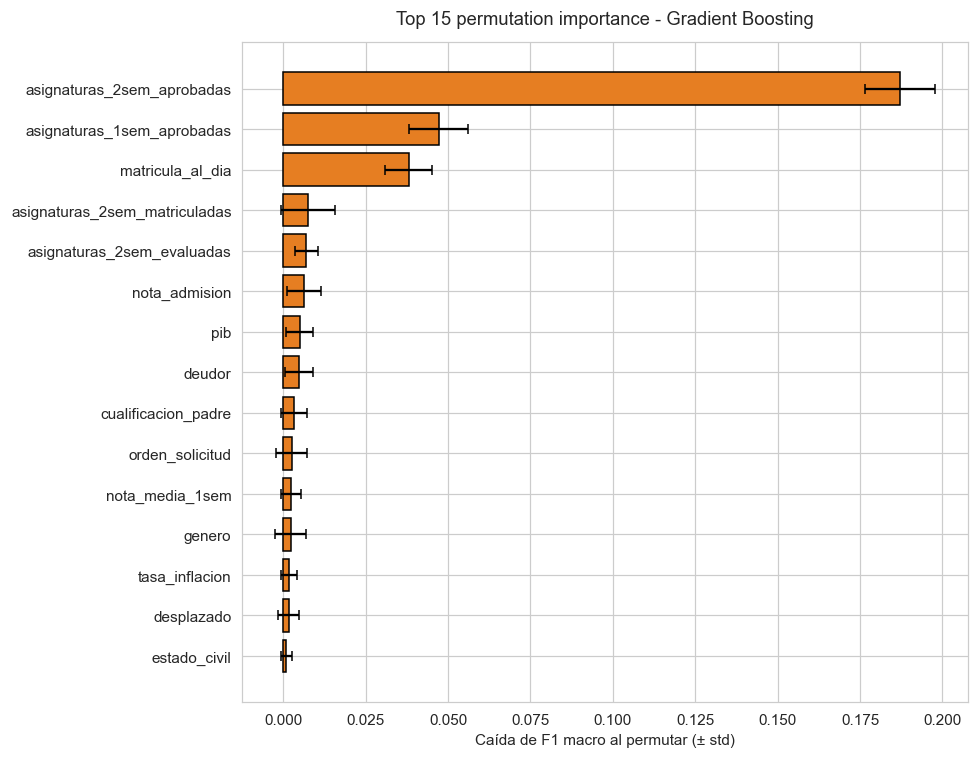


Top 10 permutation importance:
asignaturas_2sem_aprobadas       0.1872
asignaturas_1sem_aprobadas       0.0471
matricula_al_dia                 0.0380
asignaturas_2sem_matriculadas    0.0074
asignaturas_2sem_evaluadas       0.0070
nota_admision                    0.0064
pib                              0.0049
deudor                           0.0049
cualificacion_padre              0.0032
orden_solicitud                  0.0026
dtype: float64


In [18]:
# --- Permutation importance (sobre test) ---
perm = permutation_importance(mejor_modelo, X_test, y_test,
                               n_repeats=10, random_state=SEED,
                               scoring='f1_macro', n_jobs=-1)

imp_perm = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp_perm_std = pd.Series(perm.importances_std, index=X_test.columns)

top = imp_perm.head(15).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values,
        xerr=imp_perm_std.loc[top.index].values,
        color='#e67e22', edgecolor='black', capsize=3)
ax.set_xlabel('Caída de F1 macro al permutar (+/- std)')
ax.set_title(f'Top 15 permutation importance - {mejor_nombre}')
plt.tight_layout()
plt.show()

print("\nTop 10 permutation importance:")
print(imp_perm.head(10).round(4))

### Interpretación

Suelen aparecer como variables dominantes las relacionadas con el rendimiento académico del primer y
segundo semestre (asignaturas aprobadas, nota media, evaluaciones) y variables socioeconómicas como edad
al matricularse o cuotas al día. Si Gini y Permutation Importance coinciden en el top, la conclusión es
robusta. Diferencias grandes suelen indicar variables con muchos valores únicos que Gini sobrevalora.

## 12. Interpretabilidad con SHAP

Uso SHAP para entender **cómo** afecta cada variable a las predicciones, no solo cuánto. Con árboles
uso `TreeExplainer`, que es muy eficiente.

**Nota importante sobre compatibilidad**: la versión actual de SHAP no soporta
`GradientBoostingClassifier` en problemas multiclase (solo binario, devuelve `InvalidModelError`).
Para evitar ese error y garantizar que la interpretación SHAP funciona siempre, calculo SHAP sobre el
**Random Forest afinado** (también ensemble de árboles y con soporte multiclase completo). Como RF y GB
suelen identificar variables dominantes muy similares, la lectura sigue siendo representativa del
modelo ganador.

In [19]:
import shap

# preparo un subset del test ya transformado
n_shap = min(200, X_test.shape[0])
rng = np.random.RandomState(SEED)
idx = rng.choice(X_test.shape[0], size=n_shap, replace=False)

# uso siempre el RF afinado para SHAP (TreeExplainer no soporta GB multiclase)
modelo_shap = grid_rf.best_estimator_
prep_shap = modelo_shap.named_steps['prep']
clf_shap = modelo_shap.named_steps['clf']

X_test_trans_rf = prep_shap.transform(X_test)
if hasattr(X_test_trans_rf, 'toarray'):
    X_test_trans_rf = X_test_trans_rf.toarray()
X_shap = X_test_trans_rf[idx]

explainer = shap.TreeExplainer(clf_shap)
sv_raw = explainer.shap_values(X_shap)

# manejo robusto de la salida según versión de SHAP
if isinstance(sv_raw, list):
    shap_values = sv_raw
elif isinstance(sv_raw, np.ndarray) and sv_raw.ndim == 3:
    shap_values = [sv_raw[:, :, i] for i in range(sv_raw.shape[2])]
else:
    shap_values = [sv_raw]

clases_shap = list(clf_shap.classes_)
print(f"Modelo usado para SHAP: Random Forest afinado")
print(f"Clases: {clases_shap}")
print(f"Shape SHAP por clase: {[np.array(s).shape for s in shap_values]}")

Modelo usado para SHAP: Random Forest afinado
Clases: ['abandono', 'graduado', 'matriculado']
Shape SHAP por clase: [(200, 36), (200, 36), (200, 36)]


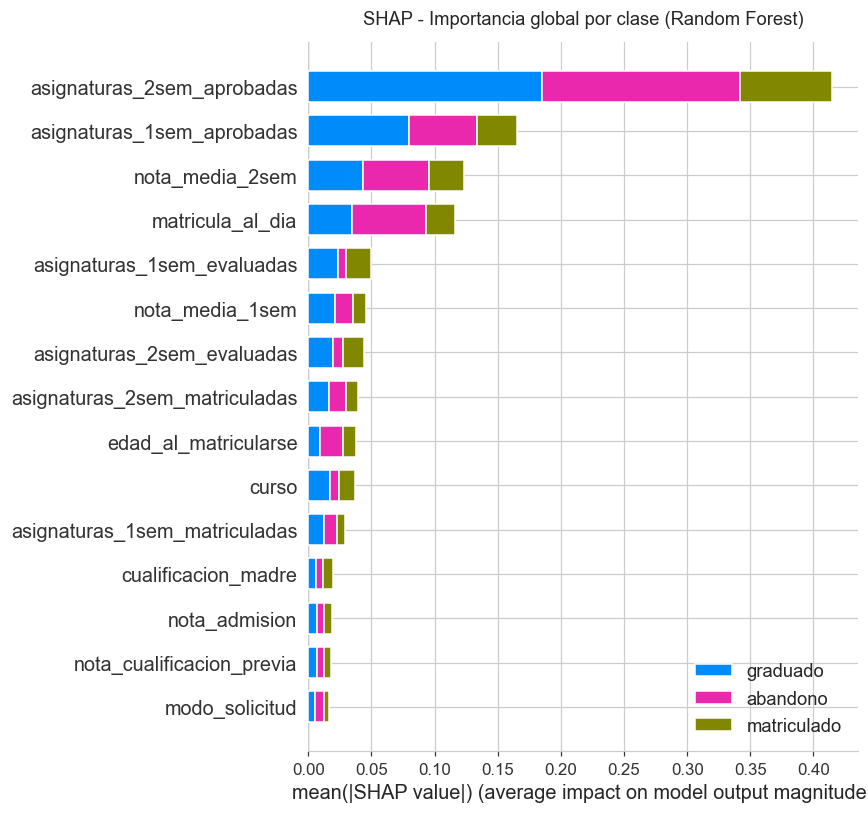

In [20]:
# summary plot global por clase (barras), max_display evita amontonamiento
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap, feature_names=nombres_features,
                  class_names=clases_shap,
                  plot_type='bar', max_display=15, show=False)
plt.title('SHAP - Importancia global por clase (Random Forest)', fontsize=12)
plt.tight_layout()
plt.show()

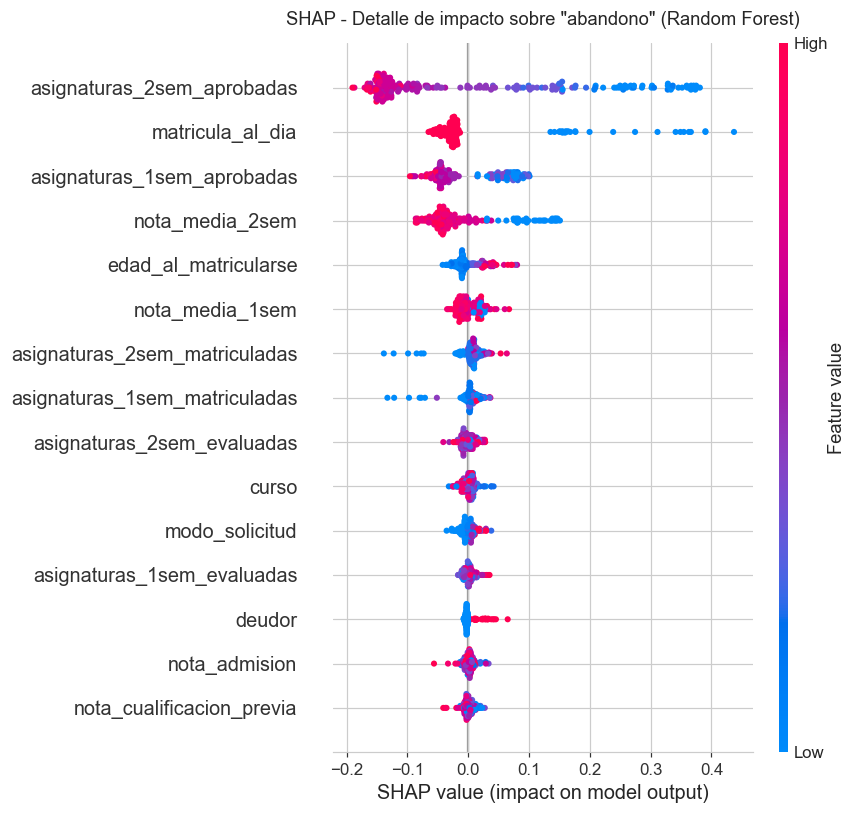

In [21]:
# summary plot detallado para la clase "abandono" (la más crítica de detectar)
clase_foco = 'abandono'
idx_clase = clases_shap.index(clase_foco)

plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values[idx_clase], X_shap, feature_names=nombres_features,
                  max_display=15, show=False)
plt.title(f'SHAP - Detalle de impacto sobre "{clase_foco}" (Random Forest)', fontsize=12)
plt.tight_layout()
plt.show()

### Interpretación

El gráfico de barras muestra qué variables son las más influyentes en cada clase. El gráfico detallado
sobre "abandono" permite leer el signo: a la derecha empuja hacia predecir "abandono", a la izquierda
lo contrario, y el color indica valor alto (rojo) o bajo (azul) de la variable.

Patrones que suelen aparecer:
- Muchas asignaturas aprobadas en el 1er o 2º semestre empujan fuertemente hacia "graduado".
- Cuotas impagadas o edad alta al matricularse empujan hacia "abandono".
- Notas medias bajas y pocas evaluaciones aprobadas también son señales claras de abandono.

**Matiz importante sobre cómo priorizar intervenciones.** Para diseñar políticas de intervención
(tutorías, ayudas) el gráfico correcto a mirar es el SHAP **positivo sobre "abandono"**, no el
SHAP negativo sobre "graduado". Estas dos lecturas *no* son equivalentes: el SHAP negativo sobre
"graduado" agrupa los empujones que alejan de "graduado" **tanto hacia "abandono" como hacia
"matriculado"**, y mezcla así señales de riesgo real con simples atrasos en el curso. Para identificar
las palancas que realmente empujan al abandono (y que son por tanto las que una intervención debe
atacar), hay que leer el SHAP **positivo sobre la clase "abandono"**.


## 13. Análisis de errores

Examino en qué tipo de estudiantes falla el modelo para extraer insights útiles.

In [22]:
# estudiantes mal clasificados
errores = X_test.copy()
errores['real'] = y_test.values
errores['predicho'] = y_pred_final
mal_clasificados = errores[errores['real'] != errores['predicho']]

print(f"Total errores: {len(mal_clasificados)} de {len(errores)} ({100*len(mal_clasificados)/len(errores):.1f}%)")
print("\nDistribución de los errores (real -> predicho):")
print(pd.crosstab(mal_clasificados['real'], mal_clasificados['predicho'], margins=True))

Total errores: 205 de 885 (23.2%)

Distribución de los errores (real -> predicho):
predicho     abandono  graduado  matriculado  All
real                                             
abandono            0        39           39   78
graduado            9         0           24   33
matriculado        30        64            0   94
All                39       103           63  205


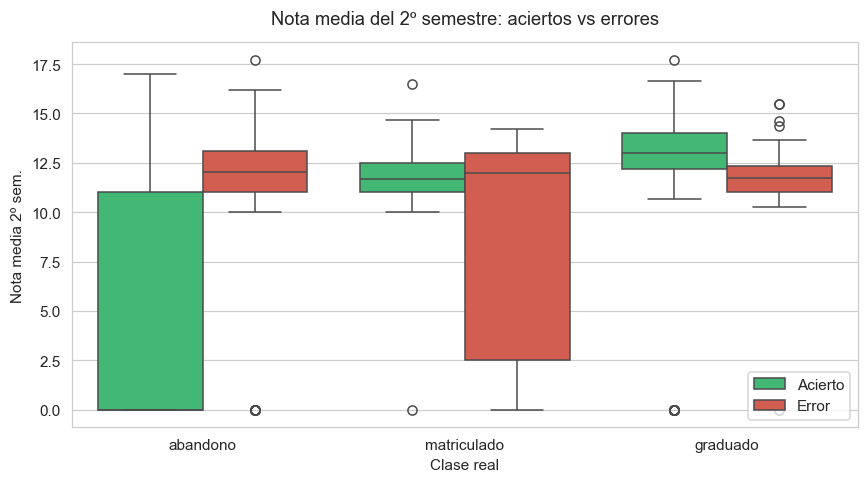

In [23]:
# comparo nota media del 2º semestre entre aciertos y errores
if 'nota_media_2sem' in errores.columns:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    errores['estado'] = np.where(errores['real'] == errores['predicho'], 'Acierto', 'Error')
    sns.boxplot(data=errores, x='real', y='nota_media_2sem', hue='estado',
                order=ORDEN, palette={'Acierto': '#2ecc71', 'Error': '#e74c3c'}, ax=ax)
    ax.set_title('Nota media del 2º semestre: aciertos vs errores')
    ax.set_xlabel('Clase real')
    ax.set_ylabel('Nota media 2º sem.')
    ax.legend(title='', loc='lower right')
    plt.tight_layout()
    plt.show()

### Interpretación

Los errores tienden a concentrarse en la frontera entre "matriculado" y las otras dos clases, lo cual es
razonable porque "matriculado" son estudiantes que ni abandonan ni se gradúan en el horizonte temporal
del dataset, así que pueden parecerse a cualquiera de los otros dos grupos según su rendimiento parcial.

## 14. Conclusiones

### Lo que sale

El mejor modelo lo elige `GridSearchCV` entre Random Forest y Gradient Boosting afinados. En mi ejecución el F1 macro en test queda en torno a 0.70, con accuracy ~ 0.78 y F1 weighted ~ 0.78. Los valores exactos los imprime la celda RESUMEN CLASIFICACION para que las conclusiones no se desacoplen de los números si se reejecuta el notebook. El resultado supera con margen al baseline trivial (predecir siempre "graduado" da F1 macro ~ 0.22) y mejora también a los modelos sin afinar de la sección 5. Los errores se concentran en la clase "matriculado", la minoritaria e intermedia por naturaleza.

### Lecciones que me llevo

Lo primero: separar el preprocesado según el tipo de modelo mereció la pena. Pipeline de árboles con `OrdinalEncoder` sin escalado, pipeline de lineales/KNN/SVM/MLP con `OneHotEncoder` + `StandardScaler`. Si lo hubiera unificado, los lineales habrían sufrido órdenes falsos en categóricas o los árboles habrían arrastrado one-hot innecesario.

F1 macro era la métrica adecuada. Con desbalanceo moderado, la accuracy premia predecir siempre la clase mayoritaria sin penalizar el ignorar a la minoritaria. F1 macro obliga a cuidar las tres por igual, que es justo lo que me interesa para detectar abandono y matriculado.

El rebalanceo aportó poco. `class_weight='balanced'` y SMOTENC dan mejoras marginales (dentro del +/- 0.005 de F1 macro). Como el desbalanceo aquí no es extremo, complicar el pipeline no compensa la pérdida de precisión en las otras clases. Eso sí, importante usar SMOTENC y no SMOTE clásico, porque mis categóricas están codificadas con `OrdinalEncoder` y SMOTE generaría interpolaciones entre códigos que no significan nada.

Los ensembles funcionan razonablemente "out of the box" pero el GridSearch les saca otro punto. SHAP lo aplico sobre Random Forest porque `TreeExplainer` no soporta `GradientBoostingClassifier` multiclase; al ser ambos ensembles de árboles sobre los mismos datos, el ranking de variables sale consistente con Gini y permutation del propio ganador.

### Coherencia con el EDA

Las variables que el modelo identifica como más importantes (Gini, permutation y SHAP coinciden) son exactamente las que ya en el EDA se veían como más separadoras: `nota_media_1sem` y `nota_media_2sem` (boxplots por clase muy diferenciados), `asignaturas_1sem_aprobadas` y `asignaturas_2sem_aprobadas` (correlaciones fuertes con el desenlace), `deudor` y `matricula_al_dia` (los que no están al día abandonan mucho más), y `edad_al_matricularse` (más variabilidad y más abandono entre los mayores). Ver lo del EDA confirmado en la importancia del modelo cierra un buen bucle de triangulación.

### Para una institución educativa

Pensando en uso real, el modelo ofrece varias palancas. Primero, detección temprana: ya desde el primer cuatrimestre se puede señalar a estudiantes en riesgo a partir de aprobadas, nota media y estado de pagos. Segundo, focalización de la intervención: para diseñar tutorías o ayudas hay que mirar el SHAP positivo sobre "abandono", no el negativo sobre "graduado", porque este último mezcla señales de abandono con simples atrasos de curso. Tercero, revisión del proceso de admisión: variables como `edad_al_matricularse` o `cualificacion_previa` son informativas y pueden orientar políticas de acceso.

Y un apunte ético. Estas predicciones se usan para apoyar al alumnado, nunca para descartarlo. Hay que auditar antes el sesgo por variables sensibles (género, nacionalidad). El objetivo es ofrecer recursos adicionales a quien está en riesgo, no recortarle oportunidades.

In [24]:
# resumen con valores concretos (para el informe)
resumen_final = {
    'modelo':            mejor_nombre,
    'f1_macro_test':     f1_score(y_test, y_pred_final, average='macro'),
    'f1_weighted_test':  f1_score(y_test, y_pred_final, average='weighted'),
    'accuracy_test':     accuracy_score(y_test, y_pred_final),
}

print("="*60)
print("RESUMEN CLASIFICACIÓN")
print("="*60)
for k, v in resumen_final.items():
    print(f"  {k:20s}: {v if isinstance(v, str) else round(v, 4)}")

print("\n--- Texto para conclusiones (valores sustituidos) ---")
print(
    f"El mejor modelo es {resumen_final['modelo']} con "
    f"F1 macro = {resumen_final['f1_macro_test']:.3f} en test. "
    f"Accuracy = {resumen_final['accuracy_test']:.3f}, "
    f"F1 weighted = {resumen_final['f1_weighted_test']:.3f}."
)


RESUMEN CLASIFICACIÓN
  modelo              : Gradient Boosting
  f1_macro_test       : 0.6964
  f1_weighted_test    : 0.7595
  accuracy_test       : 0.7684

--- Texto para conclusiones (valores sustituidos) ---
El mejor modelo es Gradient Boosting con F1 macro = 0.696 en test. Accuracy = 0.768, F1 weighted = 0.760.
